In [79]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [80]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("bhavikjikadara/loan-status-prediction")

print(f"Path to dataset files:{path}/loan_data.csv")

Using Colab cache for faster access to the 'loan-status-prediction' dataset.
Path to dataset files:/kaggle/input/loan-status-prediction/loan_data.csv


In [81]:
df = pd.read_csv(f"{path}/loan_data.csv")
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
1,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
2,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
3,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
4,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y


In [82]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 381 entries, 0 to 380
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            381 non-null    object 
 1   Gender             376 non-null    object 
 2   Married            381 non-null    object 
 3   Dependents         373 non-null    object 
 4   Education          381 non-null    object 
 5   Self_Employed      360 non-null    object 
 6   ApplicantIncome    381 non-null    int64  
 7   CoapplicantIncome  381 non-null    float64
 8   LoanAmount         381 non-null    float64
 9   Loan_Amount_Term   370 non-null    float64
 10  Credit_History     351 non-null    float64
 11  Property_Area      381 non-null    object 
 12  Loan_Status        381 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 38.8+ KB


In [83]:
df.isnull().sum()

,0
Loan_ID,0
Gender,5
Married,0
Dependents,8
Education,0
Self_Employed,21
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,11


In [84]:
null_col = df.columns[df.isnull().any()]
df[null_col]= df[null_col].fillna(df.mode().iloc[0])
df.isnull().sum()

,0
Loan_ID,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0


In [85]:
df_x = df.drop('Loan_Status', axis=1)

In [86]:
cat_col = df_x.select_dtypes(include= object).columns
num_col = df_x.select_dtypes(include= np.number).columns

In [87]:
from sklearn.preprocessing import OrdinalEncoder
oe = OrdinalEncoder()
df[cat_col] = oe.fit_transform(df[cat_col])

In [88]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['Loan_Status'] = le.fit_transform(df['Loan_Status'])

In [89]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 381 entries, 0 to 380
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            381 non-null    float64
 1   Gender             381 non-null    float64
 2   Married            381 non-null    float64
 3   Dependents         381 non-null    float64
 4   Education          381 non-null    float64
 5   Self_Employed      381 non-null    float64
 6   ApplicantIncome    381 non-null    int64  
 7   CoapplicantIncome  381 non-null    float64
 8   LoanAmount         381 non-null    float64
 9   Loan_Amount_Term   381 non-null    float64
 10  Credit_History     381 non-null    float64
 11  Property_Area      381 non-null    float64
 12  Loan_Status        381 non-null    int64  
dtypes: float64(11), int64(2)
memory usage: 38.8 KB


In [90]:
df.describe()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
count,381.000000,381.000000,381.000000,381.000000,381.000000,381.000000,381.000000,381.000000,381.000000,381.000000,381.000000,381.000000,381.000000
mean,190.000000,0.776903,0.598425,0.666667,0.270341,0.091864,3579.845144,1277.275381,104.986877,341.417323,0.850394,1.052493,0.711286
std,110.129469,0.416870,0.490861,0.987643,0.444720,0.289213,1419.813818,2340.818114,28.358464,67.625957,0.357154,0.779592,0.453761
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,150.000000,0.000000,9.000000,12.000000,0.000000,0.000000,0.000000
25%,95.000000,1.000000,0.000000,0.000000,0.000000,0.000000,2600.000000,0.000000,90.000000,360.000000,1.000000,0.000000,0.000000
50%,190.000000,1.000000,1.000000,0.000000,0.000000,0.000000,3333.000000,983.000000,110.000000,360.000000,1.000000,1.000000,1.000000
75%,285.000000,1.000000,1.000000,1.000000,1.000000,0.000000,4288.000000,2016.000000,127.000000,360.000000,1.000000,2.000000,1.000000
max,380.000000,1.000000,1.000000,3.000000,1.000000,1.000000,9703.000000,33837.000000,150.000000,480.000000,1.000000,2.000000,1.000000


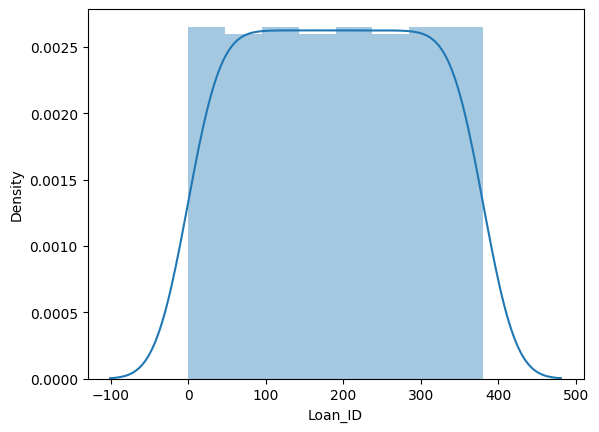

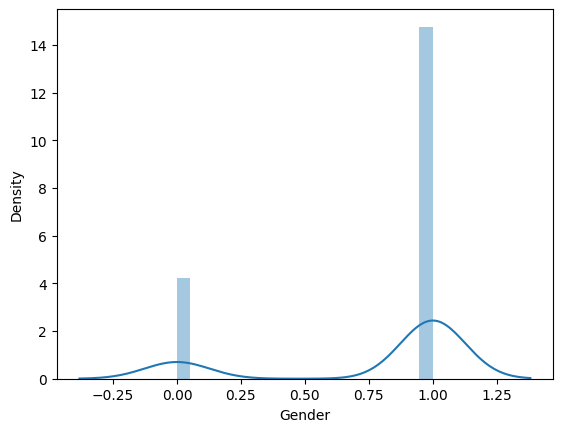

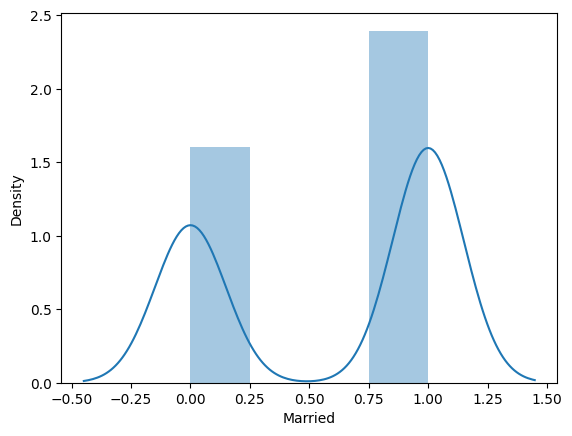

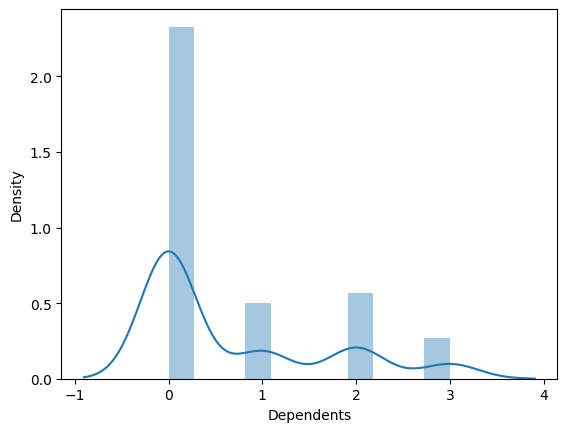

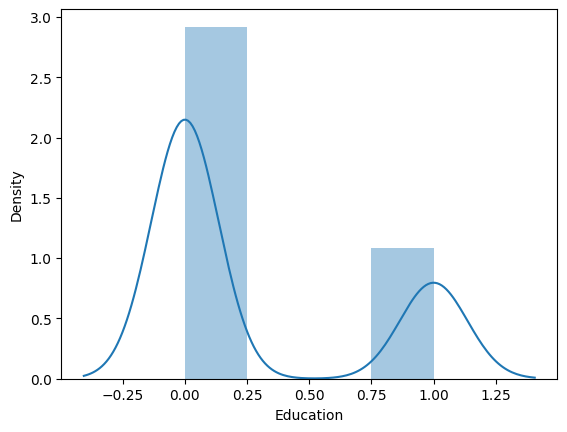

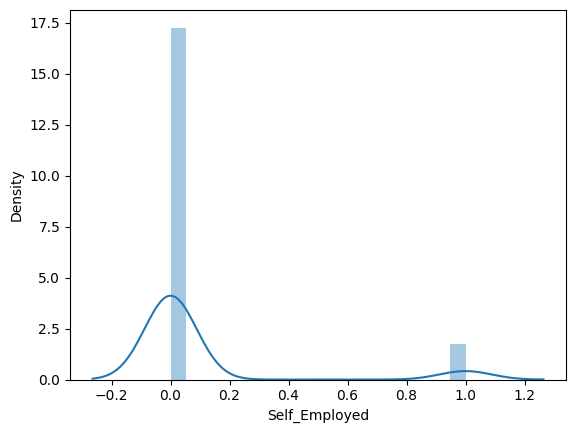

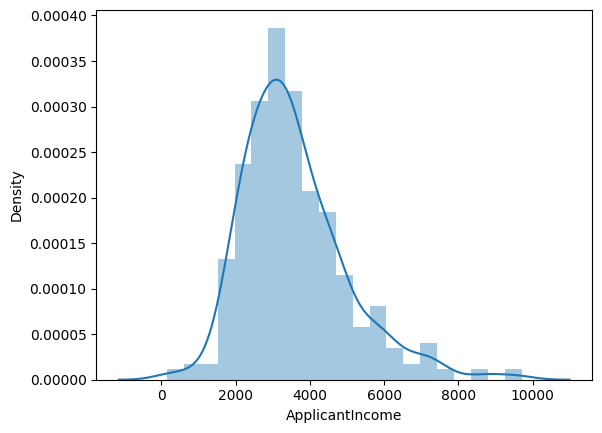

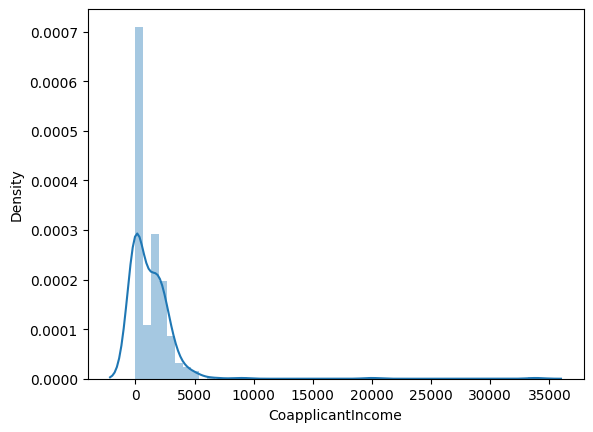

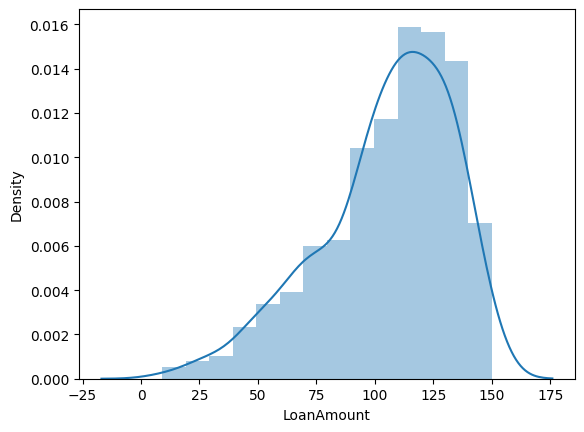

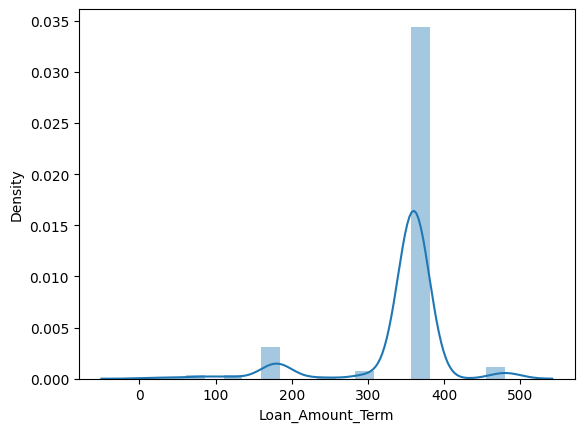

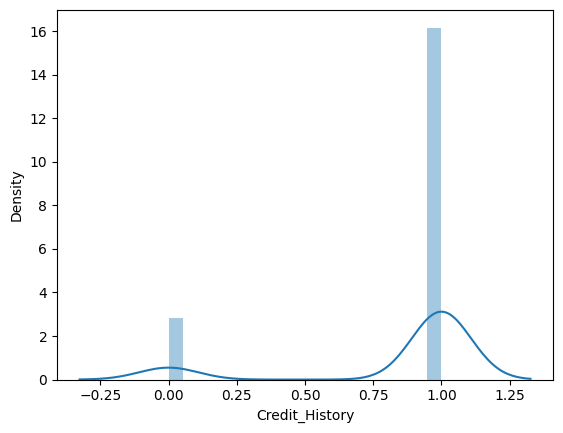

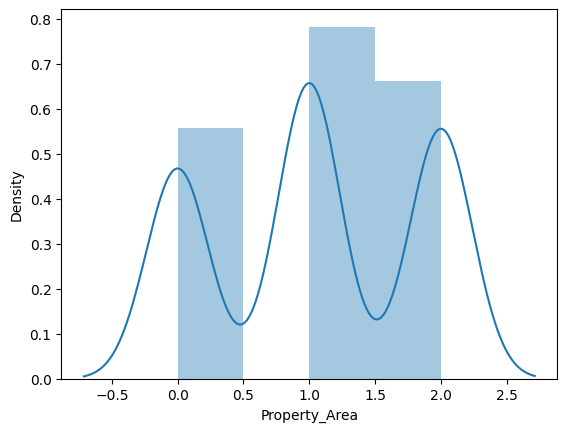

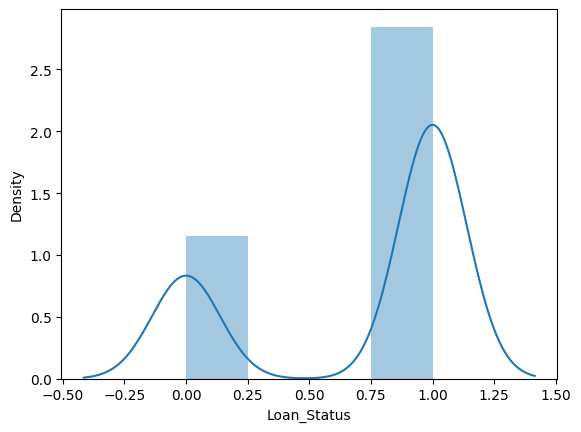

In [91]:
for col in df.columns:
  sns.distplot(df[col])
  plt.show()

In [92]:
df['CoapplicantIncome'] = np.log1p(df['CoapplicantIncome'])

<Axes: xlabel='CoapplicantIncome', ylabel='Density'>

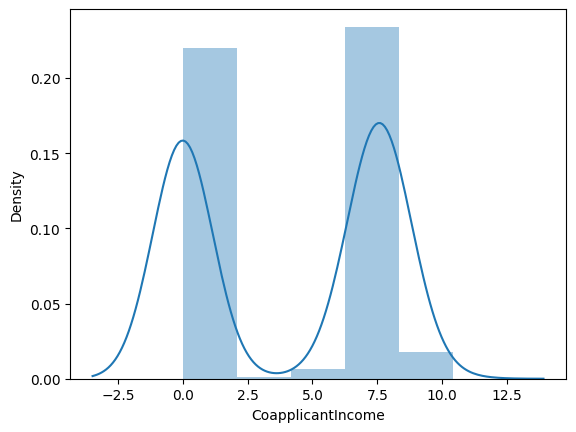

In [93]:
sns.distplot(df['CoapplicantIncome'])

In [94]:
%pip install -q outlier-tool-shashikant

In [95]:
from outlier_tool import Outliers
o = Outliers(df)

In [96]:
o.find()

,column,method,lower,upper,outliers,percent
0,Loan_ID,iqr,-190.00000,570.000000,0,0.00
1,Gender,iqr,1.00000,1.000000,85,22.31
2,Married,iqr,-1.50000,2.500000,0,0.00
3,Dependents,iqr,-1.50000,2.500000,28,7.35
4,Education,iqr,-1.50000,2.500000,0,0.00
5,Self_Employed,iqr,0.00000,0.000000,35,9.19
6,ApplicantIncome,iqr,68.00000,6820.000000,14,3.67
7,CoapplicantIncome,iqr,-11.41405,19.023416,0,0.00
8,LoanAmount,iqr,34.50000,182.500000,7,1.84
9,Loan_Amount_Term,iqr,360.00000,360.000000,58,15.22


In [97]:
df1 = o.iqr_cap()

<Axes: >

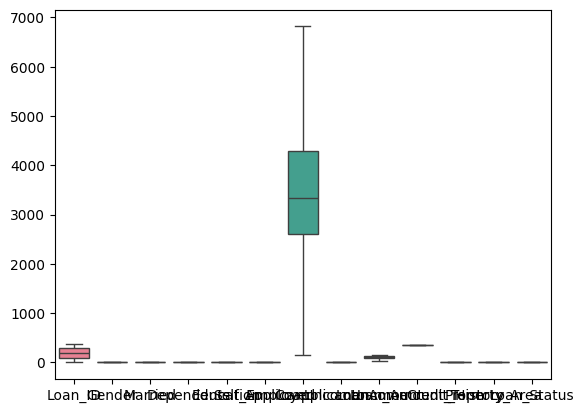

In [98]:
sns.boxplot(df1)

In [99]:
X = df1.iloc[ : , :-1]
Y = df1.iloc[ : , -1]

In [100]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)

In [102]:
from sklearn.tree import ExtraTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

ETC = ExtraTreeClassifier(max_depth=3)
ETC.fit(X_train, Y_train)
Y_pred = ETC.predict(X_test)

accuracy = accuracy_score(Y_test, Y_pred)
print("Accuracy:", accuracy)

cm = confusion_matrix(Y_test, Y_pred)
print("Confusion Matrix:\n", cm)

cr = classification_report(Y_test, Y_pred)
print("Classification Report:\n", cr)

train = ETC.score(X_train, Y_train)
print("Training Score:", train)

test = ETC.score(X_test, Y_test)
print("Testing Score:", test)

Accuracy: 0.7142857142857143
Confusion Matrix:
 [[ 0 22]
 [ 0 55]]
Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00        22
           1       0.71      1.00      0.83        55

    accuracy                           0.71        77
   macro avg       0.36      0.50      0.42        77
weighted avg       0.51      0.71      0.60        77

Training Score: 0.7105263157894737
Testing Score: 0.7142857142857143
